In [6]:
from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
DATA_PATH = Path("/home/saikat/Desktop/MLOps/Mid Term/train.csv")  # Update if needed
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_THRESHOLD = 0.5
MAX_ROWS = 200_000  # Set to None to use all rows (may require substantial RAM/time)
VALIDATION_SIZE = 0.20

TEXT_COL = "comment_text"
SCORE_COL = "target"
LABEL_COL = "toxic"

print("Dataset:", DATA_PATH.resolve())
print("Artifacts:", ARTIFACT_DIR.resolve())

Dataset: /home/saikat/Desktop/MLOps/Mid Term/train.csv
Artifacts: /home/saikat/Desktop/MLOps/Mid Term/artifacts


In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the Civil Comments CSV there "
        "or update DATA_PATH in the configuration cell."
    )

# Read only required columns to reduce memory use.
df = pd.read_csv(DATA_PATH, usecols=lambda col: col in {TEXT_COL, SCORE_COL})

missing_cols = {TEXT_COL, SCORE_COL} - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns: {sorted(missing_cols)}")

df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
df[SCORE_COL] = pd.to_numeric(df[SCORE_COL], errors="coerce")
df = df.dropna(subset=[SCORE_COL]).copy()

print("Loaded rows:", f"{len(df):,}")
display(df.head())

Loaded rows: 1,804,874


,target,comment_text
0,0.000000,"This is so cool. It's like, 'would you want yo..."
1,0.000000,Thank you!! This would make my life a lot less...
2,0.000000,This is such an urgent design problem; kudos t...
3,0.000000,Is this something I'll be able to install on m...
4,0.893617,haha you guys are a bunch of losers.


Class counts (0 = below threshold, 1 = at/above threshold):


,rows
toxic,
non-toxic-by-threshold,1660540
toxic-by-threshold,144334


Target score summary:


,target_score
count,1.804874e+06
mean,1.030173e-01
std,1.970757e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.666667e-01
max,1.000000e+00


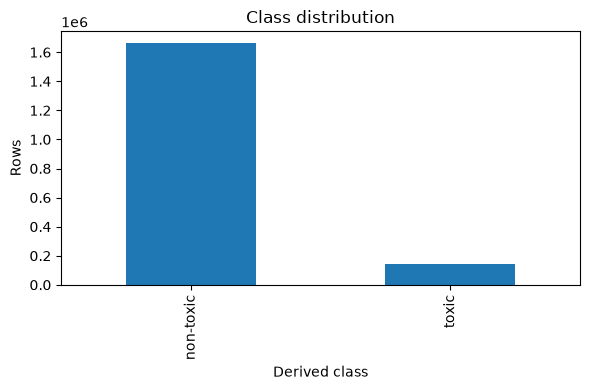

In [8]:
df[LABEL_COL] = (df[SCORE_COL] >= TARGET_THRESHOLD).astype("int8")

class_counts = df[LABEL_COL].value_counts().sort_index()
print("Class counts (0 = below threshold, 1 = at/above threshold):")
display(class_counts.rename(index={0: "non-toxic-by-threshold", 1: "toxic-by-threshold"}).to_frame("rows"))
print("Target score summary:")
display(df[SCORE_COL].describe().to_frame("target_score"))

ax = class_counts.rename(index={0: "non-toxic", 1: "toxic"}).plot(kind="bar", figsize=(6, 4))
ax.set_title("Class distribution")
ax.set_ylabel("Rows")
ax.set_xlabel("Derived class")
plt.tight_layout()
plt.show()

In [9]:
if MAX_ROWS is not None and len(df) > MAX_ROWS:
    df_model, _ = train_test_split(
        df, train_size=MAX_ROWS, random_state=RANDOM_STATE,
        stratify=df[LABEL_COL]
    )
else:
    df_model = df.copy()

df_model = df_model.reset_index(drop=True)
print("Rows used:", f"{len(df_model):,}")
display(df_model[LABEL_COL].value_counts(normalize=True).sort_index().to_frame("proportion"))

Rows used: 200,000


,proportion
toxic,
0,0.92003
1,0.07997


In [10]:
X = df_model[TEXT_COL]
y = df_model[LABEL_COL]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train rows: {len(X_train):,}")
print(f"Validation rows: {len(X_valid):,}")
print(f"Train positive rate: {y_train.mean():.3f}")
print(f"Validation positive rate: {y_valid.mean():.3f}")

Train rows: 160,000
Validation rows: 40,000
Train positive rate: 0.080
Validation positive rate: 0.080


In [11]:
word_vectorizer = TfidfVectorizer(
    lowercase=True, strip_accents="unicode", analyzer="word",
    ngram_range=(1, 2), min_df=3, max_features=200_000,
    sublinear_tf=True, dtype=np.float32
)
char_vectorizer = TfidfVectorizer(
    lowercase=True, analyzer="char", ngram_range=(3, 5),
    min_df=3, max_features=100_000, sublinear_tf=True,
    dtype=np.float32
)

start = time.time()
X_train_word = word_vectorizer.fit_transform(X_train)
X_valid_word = word_vectorizer.transform(X_valid)
X_train_char = char_vectorizer.fit_transform(X_train)
X_valid_char = char_vectorizer.transform(X_valid)

X_train_vec = hstack([X_train_word, X_train_char], format="csr", dtype=np.float32)
X_valid_vec = hstack([X_valid_word, X_valid_char], format="csr", dtype=np.float32)

print("Train feature matrix:", X_train_vec.shape)
print("Validation feature matrix:", X_valid_vec.shape)
print(f"Vectorization time: {(time.time() - start) / 60:.2f} minutes")

Train feature matrix: (160000, 300000)
Validation feature matrix: (40000, 300000)
Vectorization time: 3.82 minutes


In [12]:
model = LogisticRegression(
    C=4.0, class_weight="balanced", solver="liblinear",
    max_iter=1000, random_state=RANDOM_STATE
)

start = time.time()
model.fit(X_train_vec, y_train)
print(f"Training time: {(time.time() - start) / 60:.2f} minutes")

Training time: 2.16 minutes


,score
accuracy,0.931100
precision,0.558366
recall,0.662394
f1,0.605948
roc_auc,0.930176
average_precision,0.670007


                        precision    recall  f1-score   support

non-toxic-by-threshold       0.97      0.95      0.96     36801
    toxic-by-threshold       0.56      0.66      0.61      3199

              accuracy                           0.93     40000
             macro avg       0.76      0.81      0.78     40000
          weighted avg       0.94      0.93      0.93     40000



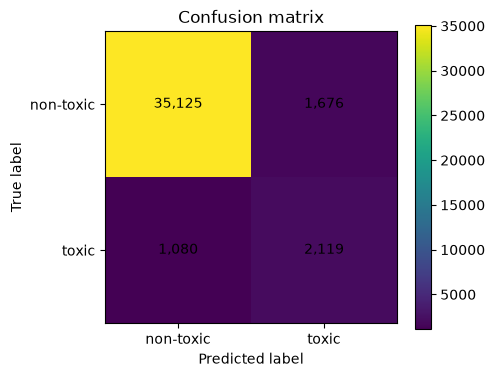

In [13]:
valid_proba = model.predict_proba(X_valid_vec)[:, 1]
valid_pred = (valid_proba >= 0.5).astype("int8")

metrics = {
    "accuracy": accuracy_score(y_valid, valid_pred),
    "precision": precision_score(y_valid, valid_pred, zero_division=0),
    "recall": recall_score(y_valid, valid_pred, zero_division=0),
    "f1": f1_score(y_valid, valid_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_valid, valid_proba),
    "average_precision": average_precision_score(y_valid, valid_proba),
}
display(pd.Series(metrics, name="score").to_frame())

print(classification_report(
    y_valid, valid_pred,
    target_names=["non-toxic-by-threshold", "toxic-by-threshold"],
    zero_division=0
))

cm = confusion_matrix(y_valid, valid_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks([0, 1], labels=["non-toxic", "toxic"])
ax.set_yticks([0, 1], labels=["non-toxic", "toxic"])
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, f"{value:,}", ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Best validation threshold: 0.6200000000000001


,value
threshold,0.620000
precision,0.625687
recall,0.604564
f1,0.614944


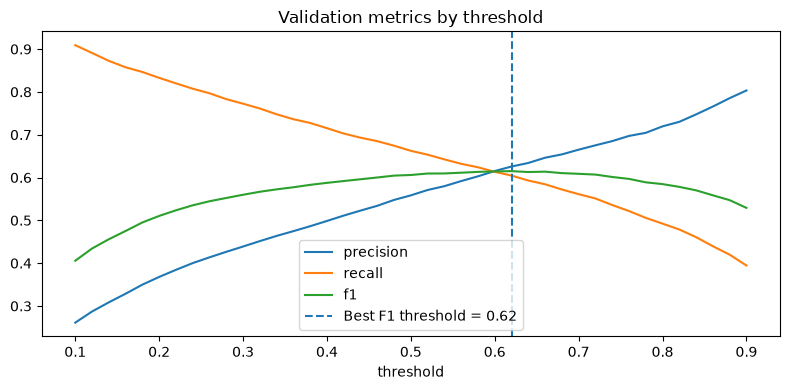

In [14]:
threshold_grid = np.arange(0.10, 0.91, 0.02)
threshold_results = []

for threshold in threshold_grid:
    pred = (valid_proba >= threshold).astype("int8")
    threshold_results.append({
        "threshold": float(threshold),
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)
best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])
print("Best validation threshold:", BEST_THRESHOLD)
display(best_row.to_frame("value"))

ax = threshold_df.plot(x="threshold", y=["precision", "recall", "f1"], figsize=(8, 4))
ax.axvline(BEST_THRESHOLD, linestyle="--", label=f"Best F1 threshold = {BEST_THRESHOLD:.2f}")
ax.set_title("Validation metrics by threshold")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
def predict_toxicity(
    texts, model=model, word_vectorizer=word_vectorizer,
    char_vectorizer=char_vectorizer, threshold=BEST_THRESHOLD
):
    if isinstance(texts, str):
        texts = [texts]
    texts = [str(text) for text in texts]

    word_features = word_vectorizer.transform(texts)
    char_features = char_vectorizer.transform(texts)
    features = hstack([word_features, char_features], format="csr", dtype=np.float32)
    probabilities = model.predict_proba(features)[:, 1]

    return pd.DataFrame({
        "comment_text": texts,
        "toxicity_probability": probabilities,
        "predicted_toxic": (probabilities >= threshold).astype("int8"),
        "threshold": threshold,
    })

display(predict_toxicity([
    "Thank you for sharing your thoughts.",
    "You are an idiot and this is a terrible idea."
]))

,comment_text,toxicity_probability,predicted_toxic,threshold
0,Thank you for sharing your thoughts.,0.07356,0,0.62
1,You are an idiot and this is a terrible idea.,1.00000,1,0.62


In [17]:
joblib.dump(word_vectorizer, ARTIFACT_DIR / "word_tfidf_vectorizer.joblib")
joblib.dump(char_vectorizer, ARTIFACT_DIR / "char_tfidf_vectorizer.joblib")
joblib.dump(model, ARTIFACT_DIR / "toxicity_logistic_regression.joblib")

metadata = {
    "model_name": "civil_comments_tfidf_logistic_regression",
    "dataset": "Jigsaw Civil Comments",
    "task": "binary toxicity classification",
    "text_column": TEXT_COL,
    "source_score_column": SCORE_COL,
    "target_column": LABEL_COL,
    "target_rule": f"target >= {TARGET_THRESHOLD}",
    "random_state": RANDOM_STATE,
    "max_rows": MAX_ROWS,
    "validation_size": VALIDATION_SIZE,
    "default_threshold": 0.5,
    "validation_best_f1_threshold": BEST_THRESHOLD,
    "validation_metrics_at_0_5": {k: float(v) for k, v in metrics.items()},
    "word_vectorizer": {
        "analyzer": "word", "ngram_range": [1, 2], "min_df": 3,
        "max_features": 200000, "sublinear_tf": True
    },
    "char_vectorizer": {
        "analyzer": "char", "ngram_range": [3, 5], "min_df": 3,
        "max_features": 100000, "sublinear_tf": True
    },
    "classifier": {
        "type": "LogisticRegression", "C": 4.0,
        "class_weight": "balanced", "solver": "liblinear", "max_iter": 1000
    },
}

with open(ARTIFACT_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved artifacts:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    if path.is_file():
        print(f"- {path} ({path.stat().st_size / (1024 * 1024):.2f} MB)")

Saved artifacts:
- artifacts/char_tfidf_vectorizer.joblib (2.91 MB)
- artifacts/model_metadata.json (0.00 MB)
- artifacts/toxicity_logistic_regression.joblib (2.29 MB)
- artifacts/word_tfidf_vectorizer.joblib (6.91 MB)


In [18]:
loaded_word_vectorizer = joblib.load(ARTIFACT_DIR / "word_tfidf_vectorizer.joblib")
loaded_char_vectorizer = joblib.load(ARTIFACT_DIR / "char_tfidf_vectorizer.joblib")
loaded_model = joblib.load(ARTIFACT_DIR / "toxicity_logistic_regression.joblib")

smoke_texts = ["A neutral comment for a smoke test.", "You are an idiot."]
word_features = loaded_word_vectorizer.transform(smoke_texts)
char_features = loaded_char_vectorizer.transform(smoke_texts)
smoke_features = hstack([word_features, char_features], format="csr", dtype=np.float32)
smoke_probabilities = loaded_model.predict_proba(smoke_features)[:, 1]

assert len(smoke_probabilities) == len(smoke_texts)
assert np.all(np.isfinite(smoke_probabilities))
assert np.all((smoke_probabilities >= 0) & (smoke_probabilities <= 1))

print("Smoke test passed.")
display(pd.DataFrame({
    "comment_text": smoke_texts,
    "toxicity_probability": smoke_probabilities,
    "predicted_toxic": (smoke_probabilities >= BEST_THRESHOLD).astype(int),
}))

Smoke test passed.


,comment_text,toxicity_probability,predicted_toxic
0,A neutral comment for a smoke test.,0.034977,0
1,You are an idiot.,1.000000,1
